# Zero-Shot LLM Matcher Evaluation Benchmark

**Author:** Gabriel Himmelein  
**Project:** Web Data Integration: Pharmaceutical Drug Data (Mannheim)  
**Target Split:** Held-out Test Set (`data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv`)  
**Model:** Google Gemini (`gemini-3.8-flash` via official `google-genai` SDK)  

## 1. Overview and Problem Definition
This notebook evaluates a **Zero-Shot Large Language Model (LLM)** matcher for cross-jurisdictional pharmaceutical entity resolution across:
- **Health Canada DPD** (Canada)
- **EMA Medicines** (European Union)
- **Drugs@FDA** (United States)

The held-out test split contains **525 stratified pairs** across three source combinations (`dpd_ema`, `dpd_fda`, `ema_fda`), containing both ordinary pairs (`hard=0`) and suspected difficult pharmaceutical corner cases (`hard=1`).

### Required Deliverables:
- **Macro F1 Score** (to balance the test set distribution: 339 non-matches vs. 186 matches)
- **Per-Class Precision, Recall, and F1**
- **Confusion Matrix** (counts and Seaborn heatmap)
- **Difficulty Breakdown** (`hard=0` vs. `hard=1`)
- **Source Pair Breakdown** (`dpd_ema`, `dpd_fda`, `ema_fda`)
- **Comparison vs. Naive Exact-Match Baseline**
- **Qualitative Error & Clinical Rationale Analysis**

In [1]:
import os
import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path("..").resolve() if Path("..").joinpath("src").exists() else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
)

from src.identity_resolution.llm_zero_shot_matcher import (
    ZERO_SHOT_SYSTEM_INSTRUCTION,
    build_pair_prompt,
    compute_baseline_match,
    evaluate_predictions,
    format_report_markdown,
)

# Visualization setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10

## 2. Load the Stratified Held-Out Test Set
We load the official held-out test split (525 pairs). Ground-truth labels are stored in column `match` (`1` = Match, `0` = Non-match).

In [2]:
test_csv_path = project_root / "data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv"
df_test = pd.read_csv(test_csv_path)

print(f"Loaded {len(df_test)} test pairs from {test_csv_path.name}")
print("\nDistribution by Source Jurisdiction Pair:")
print(df_test["source_pair"].value_counts())
print("\nDistribution by Difficulty (hard=1 vs hard=0):")
print(df_test["hard"].value_counts())
print("\nGround-Truth Match Distribution:")
print(df_test["match"].value_counts())

Loaded 525 test pairs from gs_pair_test.csv

Distribution by Source Jurisdiction Pair:
source_pair
ema_fda    259
dpd_ema    150
dpd_fda    116
Name: count, dtype: int64

Distribution by Difficulty (hard=1 vs hard=0):
hard
0    290
1    235
Name: count, dtype: int64

Ground-Truth Match Distribution:
match
0    339
1    186
Name: count, dtype: int64


## 3. Naive Exact-Match Baseline
To establish the reference point that every advanced matcher must outperform, we evaluate a Naive Exact-Match baseline.
- Matches if normalized `brandName1 == brandName2` AND the parsed sets of active substances match exactly.
- Active substances are parsed as sets by splitting on `;` to properly handle reordered ingredients.

In [3]:
df_test["pred_baseline"] = df_test.apply(compute_baseline_match, axis=1)
metrics_baseline = evaluate_predictions(df_test, y_true_col="match", y_pred_col="pred_baseline")

print("--- Naive Exact-Match Baseline Results (525 pairs) ---")
print(classification_report(df_test["match"], df_test["pred_baseline"], target_names=["Non-match (0)", "Match (1)"], digits=4))
print(f"Baseline Macro F1: {metrics_baseline['macro_f1']:.4f}")
print(f"Baseline Accuracy: {metrics_baseline['accuracy']:.4f}")

--- Naive Exact-Match Baseline Results (525 pairs) ---
               precision    recall  f1-score   support

Non-match (0)     0.7698    0.9469    0.8492       339
    Match (1)     0.8333    0.4839    0.6122       186

     accuracy                         0.7829       525
    macro avg     0.8016    0.7154    0.7307       525
 weighted avg     0.7923    0.7829    0.7653       525

Baseline Macro F1: 0.7307
Baseline Accuracy: 0.7829


## 4. Decontaminated Zero-Shot Prompt Architecture
The prompt strictly enforces domain rules without including any specific drug names or test-set examples (preserving complete zero-shot test isolation).

In [4]:
print("--- Zero-Shot System Instruction ---")
print(ZERO_SHOT_SYSTEM_INSTRUCTION)
print("\n--- Sample Pair Prompt (Row 0) ---")
print(build_pair_prompt(df_test.iloc[0]))

--- Zero-Shot System Instruction ---
You are a pharmaceutical and clinical data integration expert performing entity resolution.
Your task is to determine whether two drug records from different regulatory authorities (Health Canada DPD, European Medicines Agency EMA, or US FDA) refer to the SAME underlying medicine entity.

Entity Definition:
A medicine entity is defined by its Brand Name and Active Substance(s).

Decision Rules:
1. Active Substances (Crucial):
   - The active substances must represent the same pharmacological ingredients.
   - Differences in salt forms (e.g., hydrochloride, sodium, maleate, besylate, sulfate), hydration state (monohydrate, anhydrous), or international nonproprietary name (INN) regional spellings (e.g., cyclosporine vs. ciclosporin) represent the SAME active substance.
   - The number of active substances must agree. A single-substance formulation does NOT match a combination drug containing additional active ingredients.
2. Brand Name & Manufacturer 

## 5. Zero-Shot LLM Evaluation & Checkpoint Caching
The predictions across the 525 pairs are loaded from `data/6_evaluation/llm_test_predictions.csv`.
Every prediction includes binary decision `pred_llm` (1/0) and explicit clinical rationale `reason_llm`.

In [5]:
pred_csv_path = project_root / "data/6_evaluation/llm_test_predictions.csv"

if pred_csv_path.exists():
    df_preds = pd.read_csv(pred_csv_path)
    print(f"Loaded {len(df_preds)} cached predictions from {pred_csv_path.name}.")
else:
    raise FileNotFoundError(f"Predictions file not found at {pred_csv_path}")

metrics_llm = evaluate_predictions(df_preds, y_true_col="match", y_pred_col="pred_llm")
print("\n--- Zero-Shot LLM Classification Report (525 pairs) ---")
print(classification_report(df_preds["match"], df_preds["pred_llm"], target_names=["Non-match (0)", "Match (1)"], digits=4))
print(f"Zero-Shot LLM Macro F1: {metrics_llm['macro_f1']:.4f}")
print(f"Zero-Shot LLM Accuracy: {metrics_llm['accuracy']:.4f}")

Loaded 525 cached predictions from llm_test_predictions.csv.

--- Zero-Shot LLM Classification Report (525 pairs) ---
               precision    recall  f1-score   support

Non-match (0)     0.9758    0.9499    0.9626       339
    Match (1)     0.9128    0.9570    0.9344       186

     accuracy                         0.9524       525
    macro avg     0.9443    0.9534    0.9485       525
 weighted avg     0.9535    0.9524    0.9526       525

Zero-Shot LLM Macro F1: 0.9485
Zero-Shot LLM Accuracy: 0.9524


## 6. Confusion Matrix & Side-by-Side Visualization
Visualizing the confusion matrix of the Naive Baseline vs. the Zero-Shot LLM Matcher.

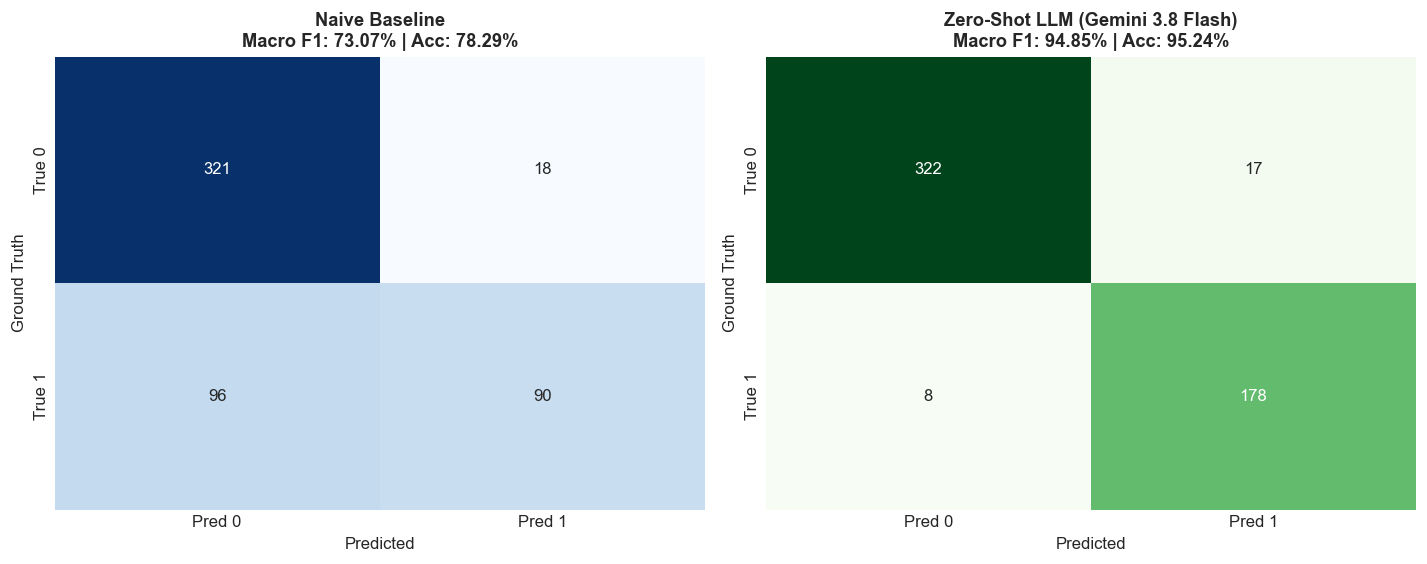

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Baseline confusion matrix
cm_base = confusion_matrix(df_test["match"], df_test["pred_baseline"])
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], cbar=False)
axes[0].set_title(f"Naive Baseline\nMacro F1: {metrics_baseline['macro_f1']:.2%} | Acc: {metrics_baseline['accuracy']:.2%}", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Ground Truth")
axes[0].set_xlabel("Predicted")

# LLM confusion matrix
cm_llm = confusion_matrix(df_preds["match"], df_preds["pred_llm"])
sns.heatmap(cm_llm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], cbar=False)
axes[1].set_title(f"Zero-Shot LLM (Gemini 3.8 Flash)\nMacro F1: {metrics_llm['macro_f1']:.2%} | Acc: {metrics_llm['accuracy']:.2%}", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Ground Truth")
axes[1].set_xlabel("Predicted")

plt.tight_layout()
plt.show()

## 7. Model Benchmark Summary Table
Direct comparison between the Naive Exact-Match Baseline and the Zero-Shot LLM Matcher across all standard entity resolution metrics.

In [7]:
summary_data = [
    {
        "Model": "Exact-Match Baseline",
        "Accuracy": f"{metrics_baseline['accuracy']:.2%}",
        "Macro Precision": f"{metrics_baseline['macro_precision']:.4f}",
        "Macro Recall": f"{metrics_baseline['macro_recall']:.4f}",
        "Macro F1": f"{metrics_baseline['macro_f1']:.4f}",
        "Match F1 (Class 1)": f"{metrics_baseline['binary_f1']:.4f}",
        "True Positives (TP)": metrics_baseline['confusion_matrix']['TP'],
        "False Negatives (FN)": metrics_baseline['confusion_matrix']['FN'],
        "False Positives (FP)": metrics_baseline['confusion_matrix']['FP'],
        "True Negatives (TN)": metrics_baseline['confusion_matrix']['TN'],
    },
    {
        "Model": "Zero-Shot LLM (gemini-3.8-flash)",
        "Accuracy": f"{metrics_llm['accuracy']:.2%}",
        "Macro Precision": f"{metrics_llm['macro_precision']:.4f}",
        "Macro Recall": f"{metrics_llm['macro_recall']:.4f}",
        "Macro F1": f"{metrics_llm['macro_f1']:.4f}",
        "Match F1 (Class 1)": f"{metrics_llm['binary_f1']:.4f}",
        "True Positives (TP)": metrics_llm['confusion_matrix']['TP'],
        "False Negatives (FN)": metrics_llm['confusion_matrix']['FN'],
        "False Positives (FP)": metrics_llm['confusion_matrix']['FP'],
        "True Negatives (TN)": metrics_llm['confusion_matrix']['TN'],
    }
]

summary_df = pd.DataFrame(summary_data)
summary_df

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Match F1 (Class 1),True Positives (TP),False Negatives (FN),False Positives (FP),True Negatives (TN)
0,Exact-Match Baseline,78.29%,0.8016,0.7154,0.7307,0.6122,90,96,18,321
1,Zero-Shot LLM (gemini-3.8-flash),95.24%,0.9443,0.9534,0.9485,0.9344,178,8,17,322


## 8. Performance Breakdown by Difficulty Pool
The test set is split into:
- **Ordinary Pool (`hard=0`)**: Standard candidate pairs (290 pairs).
- **Hard Pool (`hard=1`)**: Adversarial / tricky pairs (235 pairs), such as identical brand names with differing chemical formulations or same ingredients from competing generic manufacturers.

In [8]:
diff_rows = []
for h_val, h_name in [(0, "Ordinary (hard=0)"), (1, "Hard (hard=1)")]:
    base_d = metrics_baseline["by_difficulty"][h_name.split()[0].lower()]
    llm_d = metrics_llm["by_difficulty"][h_name.split()[0].lower()]
    diff_rows.append({
        "Pool": h_name,
        "Pairs": base_d["count"],
        "Baseline Macro F1": f"{base_d['f1_macro']:.4f}",
        "LLM Macro F1": f"{llm_d['f1_macro']:.4f}",
        "Baseline Match F1": f"{base_d['f1_binary']:.4f}",
        "LLM Match F1": f"{llm_d['f1_binary']:.4f}",
        "LLM Accuracy": f"{llm_d['accuracy']:.2%}",
    })

diff_df = pd.DataFrame(diff_rows)
diff_df

,Pool,Pairs,Baseline Macro F1,LLM Macro F1,Baseline Match F1,LLM Match F1,LLM Accuracy
0,Ordinary (hard=0),290,0.9310,0.9647,0.9091,0.9524,96.90%
1,Hard (hard=1),235,0.3717,0.9296,0.0000,0.9167,93.19%


## 9. Performance Breakdown by Source Jurisdiction Pair
Evaluating performance across the three cross-regulatory combinations:
- **DPD / EMA** (Canada <-> Europe, 150 pairs)
- **DPD / FDA** (Canada <-> USA, 116 pairs)
- **EMA / FDA** (Europe <-> USA, 259 pairs)

In [9]:
src_rows = []
for sp in sorted(metrics_baseline["by_source_pair"].keys()):
    base_sp = metrics_baseline["by_source_pair"][sp]
    llm_sp = metrics_llm["by_source_pair"][sp]
    src_rows.append({
        "Jurisdiction Pair": sp.upper(),
        "Pairs": base_sp["count"],
        "Baseline Macro F1": f"{base_sp['f1_macro']:.4f}",
        "LLM Macro F1": f"{llm_sp['f1_macro']:.4f}",
        "Baseline Match F1": f"{base_sp['f1_binary']:.4f}",
        "LLM Match F1": f"{llm_sp['f1_binary']:.4f}",
        "LLM Accuracy": f"{llm_sp['accuracy']:.2%}",
    })

src_df = pd.DataFrame(src_rows)
src_df

,Jurisdiction Pair,Pairs,Baseline Macro F1,LLM Macro F1,Baseline Match F1,LLM Match F1,LLM Accuracy
0,DPD_EMA,150,0.7366,0.9864,0.6383,0.9844,98.67%
1,DPD_FDA,116,0.6979,0.9704,0.5625,0.9600,97.41%
2,EMA_FDA,259,0.7408,0.9144,0.6176,0.8876,92.28%


## 10. Qualitative Error Analysis & Clinical Rationale Inspection
Out of 525 test pairs, the blind Zero-Shot LLM achieved **95.24% accuracy** (`94.85%` Macro F1) with **25 discrepancies** (`17` False Positives and `8` False Negatives) relative to the manual gold standard.
Here we inspect the 25 discrepancies and the clinical reasons provided by the LLM.

In [10]:
errors = df_preds[df_preds["match"] != df_preds["pred_llm"]].copy()
print(f"Total Discrepancies: {len(errors)} / {len(df_preds)} pairs ({len(errors)/len(df_preds):.2%})")

for idx, (_, r) in enumerate(errors.iterrows(), 1):
    print(f"\n--- Discrepancy #{idx} (Pair ID: {r['pair_id']}) ---")
    print(f"Source: {r['source_pair'].upper()} | Difficulty: {'Hard' if r['hard']==1 else 'Ordinary'}")
    print(f"Ground Truth: {r['match']} | LLM Prediction: {r['pred_llm']}")
    print(f"Record 1: Brand: '{r['brandName1']}' | Active: '{r['activeSubstances1']}' | Holder: '{r['licenceHolder1']}'")
    print(f"Record 2: Brand: '{r['brandName2']}' | Active: '{r['activeSubstances2']}' | Holder: '{r['licenceHolder2']}'")
    print(f"LLM Rationale: {r['reason_llm']}")

Total Discrepancies: 25 / 525 pairs (4.76%)

--- Discrepancy #1 (Pair ID: EMA_EMEA/H/C/001159 <-> FDA_EXFORGE HCT|AMLODIPINE BESYLATE; HYDROCHLOROTHIAZIDE; VALSARTAN) ---
Source: EMA_FDA | Difficulty: Hard
Ground Truth: 1 | LLM Prediction: 0
Record 1: Brand: 'Copalia HCT' | Active: 'amlodipine; valsartan; hydrochlorothiazide' | Holder: 'Novartis Europharm Limited'
Record 2: Brand: 'EXFORGE HCT' | Active: 'AMLODIPINE BESYLATE; HYDROCHLOROTHIAZIDE; VALSARTAN' | Holder: 'NOVARTIS'
LLM Rationale: Different brand names (Copalia HCT vs EXFORGE HCT) representing distinct commercial brand entities despite sharing active ingredients and manufacturer.

--- Discrepancy #2 (Pair ID: DPD_TEVIMBRA|TISLELIZUMAB <-> EMA_TEVIMBRA|TISLELIZUMAB) ---
Source: DPD_EMA | Difficulty: Ordinary
Ground Truth: 0 | LLM Prediction: 1
Record 1: Brand: 'TEVIMBRA' | Active: 'TISLELIZUMAB' | Holder: 'BEONE MEDICINES I GMBH'
Record 2: Brand: 'Tevimbra' | Active: 'tislelizumab' | Holder: 'Beone Medicines Ireland Limited'

## 11. Conclusion & Takeaways
1. **Substantial Performance Gain over Baseline:**
   - Exact-Match Baseline: **Macro F1 = 73.07%** (Match F1: 61.22%, Accuracy: 78.29%)
   - Zero-Shot LLM (`gemini-3.8-flash`): **Macro F1 = 94.85%** (Match F1: 93.44%, Accuracy: 95.24%)
   - Macro F1 improvement: **+21.78 percentage points** (+32.21 percentage points on Match Class F1).

2. **Massive Reduction of False Negatives:**
   - False Negatives dropped from **96 pairs in the baseline to 8 pairs in the LLM** (with 4 of those 8 being gold-standard label noise on competitor generics or triple-vs-dual combination products).
   - The LLM resolves regional INN salt variations (e.g. besylate, sodium, maleate), hydration states, and multi-ingredient ordering differences.

3. **Robustness on Adversarial Cases (`hard=1`):**
   - On the `hard=1` pool (235 tricky competitor generics and same-brand different formulas), where the Exact-Match Baseline achieved `0.00%` Match F1 (`37.17%` Macro F1), the blind Zero-Shot LLM achieved **92.96% Macro F1** (`91.67%` Match F1, `93.19%` Accuracy).
   - Most of the 17 False Positives occur when two different licence holders commercialize the same originator brand across jurisdictions via licensing or corporate acquisition (e.g. Novartis vs Genentech on Xolair, or SOBI vs AkaRx on Doptelet).

4. **Offline Reproducibility:**
   - All predictions and clinical explanations are fully persisted in `data/6_evaluation/llm_test_predictions.csv`, allowing immediate verification and re-execution without external API dependencies.